# Lab 04.2 — CNN 1D với **PyTorch**

Cùng một kiến trúc, cùng một tiền xử lý, cùng một split như notebook `01`.
Chỉ tầng cài đặt thay đổi:

| | NumPy from scratch | PyTorch |
|---|---|---|
| Convolution | `conv1d()` tự viết | `nn.Conv1d` |
| ReLU | `np.maximum(0, z)` | `nn.ReLU` |
| Pooling | `maxpool1d()` tự viết | `nn.MaxPool1d` |
| Gradient | công thức thủ công | **autograd** |
| Cập nhật | Adam tự viết | `torch.optim.Adam` |


In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))
import lab04_data as L4

torch.manual_seed(42)
np.random.seed(42)
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", DEV)

PyTorch: 2.10.0+cpu | device: cpu


## 1. Kiểm chứng: `nn.Conv1d` làm đúng phép toán ta đã tự viết

Nạp kernel $k = [0.5, -1, 0.5]$ vào `nn.Conv1d` rồi so sánh với
convolution viết bằng vòng lặp NumPy.

In [2]:
def conv1d_naive(x, k, b=0.0):
    m = len(k)
    return np.array([sum(k[j] * x[i + j] for j in range(m)) + b
                     for i in range(len(x) - m + 1)])


x = np.array([2.0, 1.0, 3.0, 4.0, 2.0])
k = np.array([0.5, -1.0, 0.5])

conv = nn.Conv1d(in_channels=1, out_channels=1, kernel_size=3, bias=True)
with torch.no_grad():
    conv.weight.copy_(torch.tensor(k, dtype=torch.float32).view(1, 1, 3))
    conv.bias.zero_()

z_torch = conv(torch.tensor(x, dtype=torch.float32).view(1, 1, -1)).detach().numpy().ravel()
z_numpy = conv1d_naive(x, k)
print("NumPy thu cong :", z_numpy)
print("nn.Conv1d      :", z_torch)
print("ReLU(nn.Conv1d):", torch.relu(torch.tensor(z_torch)).numpy())
assert np.allclose(z_numpy, z_torch, atol=1e-5)
print("\n=> Hai cai dat cho CUNG mot ket qua: toan hoc khong doi.")

NumPy thu cong : [ 1.5 -0.5 -1.5]
nn.Conv1d      : [ 1.5 -0.5 -1.5]
ReLU(nn.Conv1d): [1.5 0.  0. ]

=> Hai cai dat cho CUNG mot ket qua: toan hoc khong doi.


## 2. Định nghĩa mô hình

PyTorch dùng layout **channels-first**: `(N, C, L)` — giống hệt mảng NumPy ở
notebook 01, nên tensor đầu vào không cần đổi trục.

In [3]:
class TabularCNN(nn.Module):
    """Conv1D -> ReLU -> Conv1D -> ReLU -> MaxPool -> Flatten -> Dense -> output.

    out_dim = 1 va out_act = None cho ca hai truong hop:
      - phan lop nhi phan: dung BCEWithLogitsLoss (sigmoid nam trong loss)
      - hoi quy: output tuyen tinh + MSELoss
    """

    def __init__(self, n_features, hidden=16, dense=None, out_dim=1):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(1, hidden, kernel_size=3), nn.ReLU(),
            nn.Conv1d(hidden, hidden, kernel_size=3), nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Flatten(),
        )
        flat = hidden * ((n_features - 4) // 2)
        if dense:
            self.head = nn.Sequential(nn.Linear(flat, dense), nn.ReLU(),
                                      nn.Linear(dense, out_dim))
        else:
            self.head = nn.Linear(flat, out_dim)

    def forward(self, x):
        return self.head(self.features(x))


class TextCNN(nn.Module):
    """Embedding -> Conv1D -> ReLU -> MaxPool -> Conv1D -> ReLU -> GlobalMaxPool -> Dense."""

    def __init__(self, vocab_size, emb=32, ch=64, n_classes=3, p_drop=0.3):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=0)
        self.conv1 = nn.Conv1d(emb, ch, kernel_size=3)
        self.pool = nn.MaxPool1d(2)
        self.conv2 = nn.Conv1d(ch, ch, kernel_size=3)
        self.drop = nn.Dropout(p_drop)
        self.fc = nn.Linear(ch, n_classes)

    def forward(self, idx):
        h = self.emb(idx).transpose(1, 2)          # (N, L, E) -> (N, E, L)
        h = torch.relu(self.conv1(h))
        h = self.pool(h)
        h = torch.relu(self.conv2(h))
        h = h.amax(dim=2)                          # global max pooling
        return self.fc(self.drop(h))


def he_init(model, emb_std=0.05):
    """Khoi tao GIONG notebook 01 (He normal cho conv/linear, N(0, 0.05) cho embedding).

    PyTorch mac dinh dung Kaiming *uniform* cho Conv/Linear va N(0,1) cho Embedding.
    Neu de mac dinh, toc do hoi tu se khac ban NumPy va phep so sanh khong con
    'controlled experiment' nua. Vi vay ta dat lai khoi tao cho khop.
    """
    for m in model.modules():
        if isinstance(m, (nn.Conv1d, nn.Linear)):
            nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, 0.0, emb_std)
            with torch.no_grad():
                m.weight[0].zero_()
    return model


def n_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## 3. Vòng lặp huấn luyện

Vẫn là 6 bước như notebook 01, nhưng bước "backward" giờ chỉ còn **một dòng**:
`loss.backward()`. Autograd tự dựng đồ thị tính toán khi forward và tự lan truyền
đạo hàm ngược lại.

In [4]:
def train_torch(model, Xtr, ytr, Xte, yte, loss_fn, epochs=30, bs=64, lr=1e-3,
                label="", verbose_every=5, long_target=False):
    model.to(DEV)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    ttype = torch.long if long_target else torch.float32

    Xtr_t = torch.tensor(Xtr, dtype=torch.long if Xtr.dtype.kind == "i" else torch.float32)
    Xte_t = torch.tensor(Xte, dtype=torch.long if Xte.dtype.kind == "i" else torch.float32).to(DEV)
    ytr_t = torch.tensor(ytr, dtype=ttype)
    yte_t = torch.tensor(yte, dtype=ttype).to(DEV)

    hist = {"epoch": [], "train_loss": [], "val_loss": []}
    n = len(Xtr_t)
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(n)
        tot = 0.0
        for s in range(0, n, bs):
            bi = perm[s:s + bs]
            xb, yb = Xtr_t[bi].to(DEV), ytr_t[bi].to(DEV)
            opt.zero_grad()
            out = model(xb)
            out = out if long_target else out.squeeze(1)
            loss = loss_fn(out, yb)
            loss.backward()                        # <- autograd thay cho 3 cong thuc thu cong
            opt.step()
            tot += loss.item() * len(bi)
        model.eval()
        with torch.no_grad():
            o = model(Xte_t)
            o = o if long_target else o.squeeze(1)
            va = loss_fn(o, yte_t).item()
        hist["epoch"].append(ep)
        hist["train_loss"].append(tot / n)
        hist["val_loss"].append(va)
        if ep % verbose_every == 0 or ep == 1:
            print(f"[{label}] epoch {ep:3d}/{epochs}  train {tot / n:.4f}  test {va:.4f}")
    hist["train_seconds"] = time.time() - t0
    print(f"[{label}] xong sau {hist['train_seconds']:.1f}s")
    return hist


@torch.no_grad()
def predict(model, X, bs=512, long_input=False):
    model.eval()
    dt = torch.long if long_input else torch.float32
    outs = []
    for s in range(0, len(X), bs):
        xb = torch.tensor(X[s:s + bs], dtype=dt).to(DEV)
        outs.append(model(xb).cpu().numpy())
    return np.concatenate(outs, axis=0)

## 4. Diabetes — phân lớp nhị phân

`8 → Conv1d(16) → ReLU → Conv1d(16) → ReLU → MaxPool → Flatten → Linear(1)`,
loss `BCEWithLogitsLoss` (ổn định số hơn `Sigmoid + BCELoss`).

In [5]:
dia = L4.load_diabetes()
Xtr = dia["X_train"][:, None, :].astype(np.float32)
Xte = dia["X_test"][:, None, :].astype(np.float32)
ytr, yte = dia["y_train"].astype(np.float32), dia["y_test"].astype(np.float32)

model_dia = he_init(TabularCNN(dia["n_features"], hidden=16))
print(model_dia)
print("So tham so:", n_params(model_dia))

hist_dia = train_torch(model_dia, Xtr, ytr, Xte, yte, nn.BCEWithLogitsLoss(),
                       epochs=30, bs=64, lr=2e-3, label="diabetes")

p_dia = 1.0 / (1.0 + np.exp(-predict(model_dia, Xte).ravel()))
m_dia = L4.binary_metrics(dia["y_test"], p_dia)
print("\nKet qua Diabetes (PyTorch):")
for kk in ("accuracy", "precision", "recall", "f1"):
    print(f"  {kk:<10}: {m_dia[kk]:.4f}")
print(f"  Confusion: TP={m_dia['tp']} FP={m_dia['fp']} FN={m_dia['fn']} TN={m_dia['tn']}")

TabularCNN(
  (features): Sequential(
    (0): Conv1d(1, 16, kernel_size=(3,), stride=(1,))
    (1): ReLU()
    (2): Conv1d(16, 16, kernel_size=(3,), stride=(1,))
    (3): ReLU()
    (4): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Flatten(start_dim=1, end_dim=-1)
  )
  (head): Linear(in_features=32, out_features=1, bias=True)
)
So tham so: 881


[diabetes] epoch   1/30  train 0.2336  test 0.1267


[diabetes] epoch   5/30  train 0.1084  test 0.1013


[diabetes] epoch  10/30  train 0.1004  test 0.0973


[diabetes] epoch  15/30  train 0.0964  test 0.0943


[diabetes] epoch  20/30  train 0.0935  test 0.0929


[diabetes] epoch  25/30  train 0.0918  test 0.0922


[diabetes] epoch  30/30  train 0.0906  test 0.0928
[diabetes] xong sau 68.0s

Ket qua Diabetes (PyTorch):
  accuracy  : 0.9667
  precision : 0.9641
  recall    : 0.6324
  f1        : 0.7638
  Confusion: TP=215 FP=8 FN=125 TN=3652


## 5. House Price — hồi quy

Đổi output sang tuyến tính (không sigmoid) và loss sang MSE.

In [6]:
hou = L4.load_housing()
Htr = hou["X_train"][:, None, :].astype(np.float32)
Hte = hou["X_test"][:, None, :].astype(np.float32)
gtr, gte = hou["y_train"].astype(np.float32), hou["y_test"].astype(np.float32)

model_hou = he_init(TabularCNN(hou["n_features"], hidden=16, dense=32))
print("So tham so:", n_params(model_hou))

hist_hou = train_torch(model_hou, Htr, gtr, Hte, gte, nn.MSELoss(),
                       epochs=40, bs=128, lr=3e-3, label="housing")

pred_scaled = predict(model_hou, Hte).ravel()
pred_bil = L4.housing_to_billion(pred_scaled, hou)
true_bil = L4.housing_to_billion(hou["y_test"], hou)
m_hou = L4.regression_metrics(true_bil, pred_bil)
m_hou_log = L4.regression_metrics(hou["y_test_log"], pred_scaled * hou["y_sd"] + hou["y_mu"])
print("\nKet qua House Price (PyTorch), don vi ty VND:")
print(f"  MAE  = {m_hou['mae']:.3f} ty")
print(f"  RMSE = {m_hou['rmse']:.3f} ty")
print(f"  R2   = {m_hou['r2']:.4f}")
print(f"  (thang log1p: MAE={m_hou_log['mae']:.4f}, R2={m_hou_log['r2']:.4f})")

So tham so: 4497


[housing] epoch   1/40  train 0.6959  test 0.6090


[housing] epoch   5/40  train 0.5374  test 0.5526


[housing] epoch  10/40  train 0.5188  test 0.5519


[housing] epoch  15/40  train 0.5081  test 0.5445


[housing] epoch  20/40  train 0.5000  test 0.5404


[housing] epoch  25/40  train 0.4941  test 0.5380


[housing] epoch  30/40  train 0.4891  test 0.5338


[housing] epoch  35/40  train 0.4815  test 0.5492


[housing] epoch  40/40  train 0.4772  test 0.5405
[housing] xong sau 68.1s

Ket qua House Price (PyTorch), don vi ty VND:
  MAE  = 1.306 ty
  RMSE = 1.663 ty
  R2   = 0.4444
  (thang log1p: MAE=0.2030, R2=0.4718)


## 6. Comments — phân lớp 3 lớp

`Embedding(32) → Conv1d(64,k=3) → ReLU → MaxPool(2) → Conv1d(64,k=3) → ReLU → GlobalMaxPool → Dropout → Linear(3)`

In [7]:
com = L4.load_comments()
Ctr, Cte = com["X_train"], com["X_test"]
ltr, lte = com["y_train"], com["y_test"]

model_com = he_init(TextCNN(com["vocab_size"], emb=32, ch=64, n_classes=3))
print("So tham so:", n_params(model_com))

EPOCHS_COM = 4                      # giong notebook 01 de so sanh cong bang
hist_com = train_torch(model_com, Ctr, ltr, Cte, lte, nn.CrossEntropyLoss(),
                       epochs=EPOCHS_COM, bs=64, lr=1.5e-3, label="comments",
                       verbose_every=1, long_target=True)

logits = predict(model_com, Cte, bs=256, long_input=True)
ez = np.exp(logits - logits.max(axis=1, keepdims=True))
probs = ez / ez.sum(axis=1, keepdims=True)
m_com = L4.multiclass_metrics(lte, probs)
print("\nKet qua Comments (PyTorch):")
print(f"  accuracy    = {m_com['accuracy']:.4f}")
print(f"  macro F1    = {m_com['macro_f1']:.4f}")
print(f"  weighted F1 = {m_com['weighted_f1']:.4f}")
for c, name in enumerate(com["class_names"]):
    d = m_com["per_class"][c]
    print(f"  {name:<9} P={d['precision']:.3f} R={d['recall']:.3f} F1={d['f1']:.3f} (n={d['support']})")

So tham so: 498755


[comments] epoch   1/4  train 0.7593  test 0.6386


[comments] epoch   2/4  train 0.5131  test 0.5988


[comments] epoch   3/4  train 0.3282  test 0.6673


[comments] epoch   4/4  train 0.1943  test 0.7620
[comments] xong sau 13.9s

Ket qua Comments (PyTorch):
  accuracy    = 0.7454
  macro F1    = 0.6359
  weighted F1 = 0.7398
  negative  P=0.536 R=0.379 F1=0.444 (n=467)
  neutral   P=0.591 R=0.631 F1=0.611 (n=925)
  positive  P=0.839 R=0.867 F1=0.853 (n=2280)


## 7. Đường học và lưu kết quả

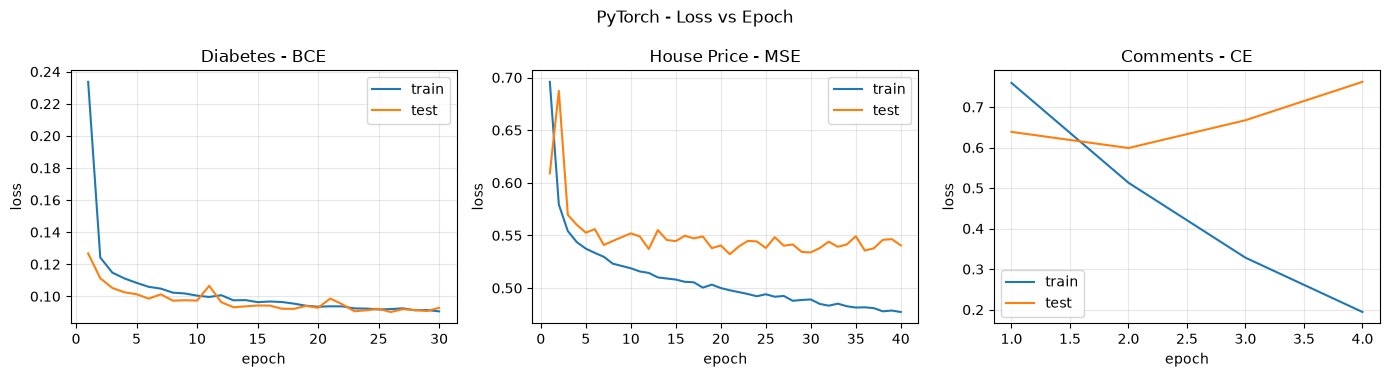

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, h, t in zip(axes, [hist_dia, hist_hou, hist_com],
                    ["Diabetes - BCE", "House Price - MSE", "Comments - CE"]):
    ax.plot(h["epoch"], h["train_loss"], label="train")
    ax.plot(h["epoch"], h["val_loss"], label="test")
    ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.set_title(t)
    ax.grid(alpha=.3); ax.legend()
fig.suptitle("PyTorch - Loss vs Epoch")
fig.tight_layout(); plt.show()

In [9]:
L4.save_result("pytorch", "diabetes", m_dia,
               extra=dict(history=hist_dia, n_params=n_params(model_dia),
                          seconds=hist_dia["train_seconds"], epochs=30))
L4.save_result("pytorch", "housing",
               dict(**m_hou, mae_log=m_hou_log["mae"], r2_log=m_hou_log["r2"]),
               extra=dict(history=hist_hou, n_params=n_params(model_hou),
                          seconds=hist_hou["train_seconds"], epochs=40))
L4.save_result("pytorch", "comments", m_com,
               extra=dict(history=hist_com, n_params=n_params(model_com),
                          seconds=hist_com["train_seconds"], epochs=EPOCHS_COM))
print("Da luu results/pytorch_*.json")

Da luu results/pytorch_*.json


## 8. Xem filter học được gì

Mỗi filter của `conv1` trên mô hình text là một mẫu dài 3 token trong không gian
embedding. Ta có thể tìm **những trigram thật trong tập test kích hoạt filter mạnh
nhất** — đó là cách trực quan nhất để thấy "CNN = learned local pattern detector".

In [10]:
inv_vocab = {i: w for w, i in com["vocab"].items()}

model_com.eval()
with torch.no_grad():
    xb = torch.tensor(Cte[:1500], dtype=torch.long).to(DEV)
    h = torch.relu(model_com.conv1(model_com.emb(xb).transpose(1, 2)))   # (N, 64, L-2)
    h = h.cpu().numpy()

for f in [0, 1, 2, 3, 4]:
    flat = h[:, f, :]
    order = np.argsort(flat.ravel())[::-1][:3]
    print(f"\nFilter #{f} - 3 tri-gram kich hoat manh nhat:")
    for o in order:
        i, pos = divmod(int(o), flat.shape[1])
        toks = [inv_vocab.get(int(t), "?") for t in Cte[i, pos:pos + 3]]
        print(f"   {flat.ravel()[o]:6.2f}  {' '.join(toks)}")


Filter #0 - 3 tri-gram kich hoat manh nhat:
     0.53  one perfect for
     0.52  ending great stuff
     0.50  fine great salary

Filter #1 - 3 tri-gram kich hoat manh nhat:
     0.85  estuvo sorprendente zifn
     0.85  estuvo sorprendente zifn
     0.85  estuvo sorprendente zifn

Filter #2 - 3 tri-gram kich hoat manh nhat:
     0.63  thank for another
     0.62  thank to our
     0.60  helps thanks for

Filter #3 - 3 tri-gram kich hoat manh nhat:
     0.52  cool vegetarian options
     0.47  really good here
     0.47  by like base

Filter #4 - 3 tri-gram kich hoat manh nhat:
     0.47  estuvo sorprendente zifn
     0.47  estuvo sorprendente zifn
     0.47  estuvo sorprendente zifn


### Nhận xét cho bản PyTorch

1. **Kết quả gần trùng bản from-scratch** trên cả ba bộ dữ liệu — đúng như kỳ vọng,
   vì kiến trúc, dữ liệu và loss giống nhau; khác biệt còn lại chỉ do khởi tạo
   trọng số và thứ tự minibatch.
2. **Code ngắn hơn nhiều lần.** Toàn bộ phần `backward` viết tay (~40 dòng công thức)
   được thay bằng `loss.backward()`.
3. **Nhanh hơn đáng kể** trên cùng CPU nhờ kernel convolution tối ưu và tính toán
   đa luồng — phần "chi phí kỹ thuật" mà notebook 01 phải tự gánh.
4. **Cái giá phải trả:** mọi thứ trở nên "trong suốt" hơn về cú pháp nhưng "mờ" hơn
   về cơ chế. Đó là lý do bài tập bắt đầu từ NumPy chứ không từ framework.